In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv')

In [29]:
updated_df = df[['age','indus','tax','rm','medv']]
updated_df.sample(5)

,age,indus,tax,rm,medv
29,87.3,8.14,307,6.674,21.0
73,6.2,10.81,305,6.245,23.4
44,40.0,6.91,233,6.069,21.2
63,43.4,5.13,284,6.762,25.0
51,63.0,5.64,243,6.115,20.5


C:\Users\Zahoor\AppData\Local\Temp\ipykernel_20428\3572190911.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(updated_df['age'])
C:\Users\Zahoor\AppData\Local\Temp\ipykernel_20428\3572190911.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(updated_df['indus'])


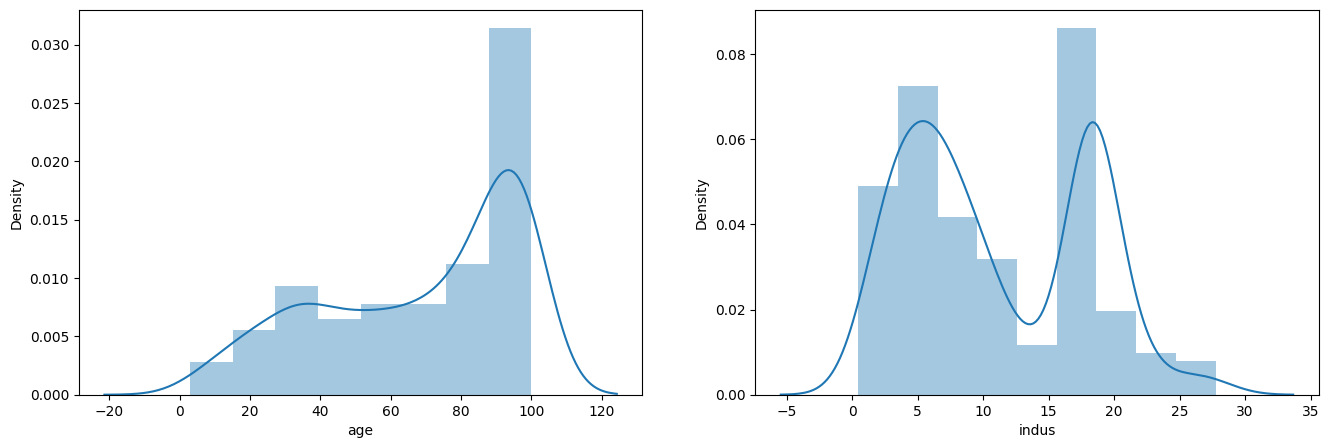

In [30]:
plt.figure(figsize=(16,5))
plt.subplot(1,2,1)
sns.distplot(updated_df['age'])

plt.subplot(1,2,2)
sns.distplot(updated_df['indus'])

plt.show()

C:\Users\Zahoor\AppData\Local\Temp\ipykernel_20428\322099181.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['rm'])


<Axes: xlabel='rm', ylabel='Density'>

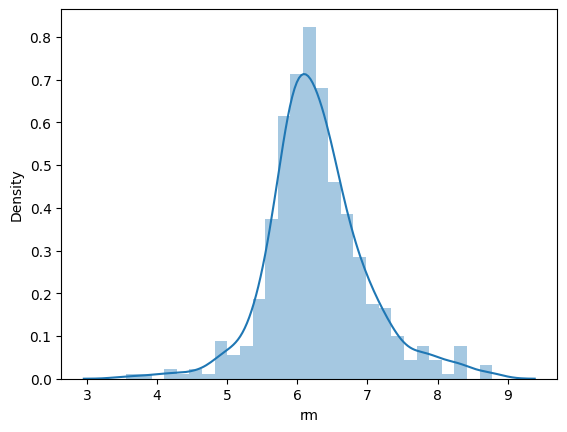

In [20]:
sns.distplot(df['rm'])

C:\Users\Zahoor\AppData\Local\Temp\ipykernel_20428\538125548.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['medv'])


<Axes: xlabel='medv', ylabel='Density'>

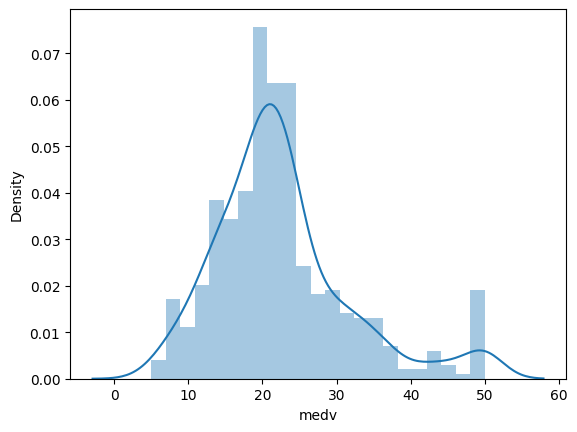

In [28]:
sns.distplot(df['medv'])

In [12]:
df.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [18]:
df['rm'].skew()

np.float64(0.40361213328874385)

In [31]:
df['medv'].skew()

np.float64(1.1080984082549072)

In [9]:
df['tax'].skew()

np.float64(0.669955941795016)

In [35]:
updated_df[(updated_df['rm'] > rm_higher_limit) | (updated_df['rm'] < rm_lower_limit)]

,age,indus,tax,rm,medv
225,83.0,6.20,307,8.725,50.0
257,86.9,3.97,264,8.704,50.0
262,91.5,3.97,264,8.398,48.8
364,82.9,18.10,666,8.780,21.9
365,87.9,18.10,666,3.561,27.5
367,100.0,18.10,666,3.863,23.1
374,100.0,18.10,666,4.138,13.8
406,100.0,18.10,666,4.138,11.9


# Trimming

In [36]:
outlier_free_df =updated_df[(updated_df['rm'] <= rm_higher_limit) & (updated_df['rm'] >= rm_lower_limit)]

In [40]:
outlier_free_df.describe()

,age,indus,tax,rm,medv
count,498.000000,498.000000,498.000000,498.000000,498.000000
mean,68.206225,11.105562,406.431727,6.284574,22.398795
std,28.208143,6.861306,167.588615,0.641150,9.004110
min,2.900000,0.460000,187.000000,4.368000,5.000000
25%,43.875000,5.190000,279.000000,5.888000,17.025000
50%,76.700000,9.690000,330.000000,6.208500,21.150000
75%,93.975000,18.100000,666.000000,6.617500,25.000000
max,100.000000,27.740000,711.000000,8.375000,50.000000


In [39]:
# checking the minimum and maximum values of the before and after outlier removal
print("Before outlier removal - Min:", df['rm'].min(), "Max:", df['rm'].max())
print("After outlier removal - Min:", outlier_free_df['rm'].min(), "Max:", outlier_free_df['rm'].max())

Before outlier removal - Min: 3.561 Max: 8.78
After outlier removal - Min: 4.368 Max: 8.375


## Cappimg

In [43]:
rm_higher_limit = updated_df['rm'].mean() + 3* updated_df['rm'].std()
rm_lower_limit = updated_df['rm'].mean() - 3* updated_df['rm'].std()

In [44]:
print("rm higher limit is: ", rm_higher_limit)
print("rm lower limit is: ", rm_lower_limit)

rm higher limit is:  8.39248581759775
rm lower limit is:  4.176782957105807


In [46]:
outlier_free_df1 = np.where(
    updated_df['rm'] > rm_higher_limit,
    rm_higher_limit,
    np.where(
        updated_df['rm'] < rm_lower_limit,
        rm_lower_limit,
        updated_df['rm']
    )
)

In [51]:
print("min vale of rm after outlier removal is: ", outlier_free_df1.min())

min vale of rm after outlier removal is:  4.176782957105807


In [49]:
updated_df.describe()

,age,indus,tax,rm,medv
count,506.000000,506.000000,506.000000,506.000000,506.000000
mean,68.574901,11.136779,408.237154,6.284634,22.532806
std,28.148861,6.860353,168.537116,0.702617,9.197104
min,2.900000,0.460000,187.000000,3.561000,5.000000
25%,45.025000,5.190000,279.000000,5.885500,17.025000
50%,77.500000,9.690000,330.000000,6.208500,21.200000
75%,94.075000,18.100000,666.000000,6.623500,25.000000
max,100.000000,27.740000,711.000000,8.780000,50.000000
